# Taller 1 — Notebook 04: Criterios de focalización

**MINE-4101 · Ciencia de Datos Aplicada**

Cubre el **punto 4 (25 %)** del taller: convierte los hallazgos del notebook 03 en criterios que
la oficina de control interno pueda aplicar, y cuantifica lo que gana al usarlos.

**Requisito:** ejecutar antes [`01_entendimiento_datos.ipynb`](01_entendimiento_datos.ipynb).

**Herramientas.** Solo las vistas en clase: tasas por grupo, intervalos de confianza del 95 %, la
correlación y los contrastes del notebook 03. No se usan modelos predictivos.

El producto son tres entregables operativos:

1. Una **tabla de riesgo valor × modalidad**: la tasa de desviación de cada combinación, con su
   intervalo de confianza, aplicable a mano desde la firma del contrato.
2. **Dos niveles de supervisión** con su costo y su cobertura, para elegir cuánto supervisar.
3. Un **frente separado de calidad del reporte**, que el análisis reveló como el problema de
   mayor tamaño de efecto.

In [1]:
import sys
import warnings
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.lines import Line2D

RAIZ = Path.cwd().parent if Path.cwd().name == "notebooks" else Path.cwd()
sys.path.insert(0, str(RAIZ))

from src import config
from src.carga import cargar_limpio
from src.inferencia import agrupar_raras, prueba_correlacion
from src.viz import AZUL, AZUL_CLARO, GRIS, NARANJA, ROJO, aplicar_estilo, guardar

warnings.filterwarnings("ignore", category=FutureWarning)
aplicar_estilo()
config.asegurar_directorios()
pd.set_option("display.width", 190)
np.random.seed(config.SEMILLA)

df = cargar_limpio()
print(f"{len(df):,} contratos · tasa base de desviación "
      f"{100*df['desviacion'].mean():.2f} %")

  dataset limpio: 196,391 filas x 70 columnas


196,391 contratos · tasa base de desviación 13.55 %


---
## 1. La tabla de riesgo: valor × modalidad

El notebook 03 dejó dos atributos con efecto utilizable: el **valor del contrato** (H2 y H2b) y la
**modalidad de contratación** (H1). Es el uso de las pruebas de hipótesis que la clase llama
*selección de características por filtrado*: de todos los atributos candidatos, solo esos dos
superan el umbral de relevancia fijado a priori. El resto quedó descartado: el destino del gasto
por el control por composición (§12), el sector y el tipo de entidad por su tamaño de efecto (H4 y
§13).

Aquí se cruzan en una tabla. Cada combinación de modalidad y rango de valor recibe su tasa de
desviación y su **intervalo de confianza del 95 %**, calculado como en clase: estimación ± Z ×
error estándar, con el error estándar de una proporción, √(p(1 − p)/n).

Las combinaciones con menos de 300 contratos tienen intervalos demasiado anchos para ordenar con
ellas. Para esas pocas, la regla usa la tasa de su rango de valor, que es el atributo dominante.

In [2]:
CORTES = [0, 10e6, 50e6, 200e6, 1000e6, np.inf]
ETIQ = ["< 10 M", "10–50 M", "50–200 M", "200–1.000 M", "> 1.000 M"]
ETIQ_TEXTO = dict(zip(ETIQ, ["menos de 10 millones", "10 a 50 millones", "50 a 200 millones",
                             "200 a 1.000 millones", "más de 1.000 millones"]))
MIN_N = 300   # por debajo, el IC 95 % de una tasa puede pasar de ±5,7 puntos

d = df.copy()
d["banda_valor"] = pd.cut(d["valor_del_contrato"], CORTES, labels=ETIQ, right=False)
d["modalidad"] = agrupar_raras(d["modalidad_de_contratacion"], 0.01)
ANTES = len(d)
d = d.dropna(subset=["banda_valor", "modalidad", "desviacion"])
d["y"] = d["desviacion"].astype(int)
BASE = d["y"].mean()
print(f"contratos: {len(d):,}  (descartados {ANTES - len(d):,} sin valor o sin modalidad)"
      f"  ·  tasa base {100 * BASE:.2f} %")

tabla = (d.groupby(["modalidad", "banda_valor"], observed=True)["y"]
         .agg(contratos="size", desviaciones="sum", tasa="mean").reset_index())
# IC 95 % de una proporcion: p ± 1,96 · raiz(p(1 - p) / n).
ee = np.sqrt(tabla["tasa"] * (1 - tabla["tasa"]) / tabla["contratos"])
tabla["tasa_%"] = 100 * tabla["tasa"]
tabla["IC_lo_%"] = 100 * (tabla["tasa"] - 1.96 * ee)
tabla["IC_hi_%"] = 100 * (tabla["tasa"] + 1.96 * ee)
tabla["estable"] = tabla["contratos"] >= MIN_N
# La regla usa la tasa de la combinacion si es estable; si no, la de su rango de valor.
tasa_rango = d.groupby("banda_valor", observed=True)["y"].mean()
tabla["tasa_regla_%"] = np.where(tabla["estable"], tabla["tasa_%"],
                                 100 * tabla["banda_valor"].map(tasa_rango).astype(float))
tabla["eficiencia"] = tabla["tasa_regla_%"] / (100 * BASE)
tabla = (tabla.drop(columns="tasa").sort_values("tasa_regla_%", ascending=False)
         .reset_index(drop=True))

tabla.round(2).to_csv(config.TABLAS / "combinaciones_riesgo.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/combinaciones_riesgo.csv")
print(f"combinaciones: {len(tabla)}   con al menos {MIN_N} contratos: {tabla['estable'].sum()}"
      f"   contratos en las demás: {tabla.loc[~tabla['estable'], 'contratos'].sum():,}")
estables = tabla[tabla["estable"]]
semi = (estables["IC_hi_%"] - estables["IC_lo_%"]) / 2
print(f"semiancho máximo del IC 95 % en las combinaciones estables: ±{semi.max():.1f} puntos")

COLS = ["modalidad", "banda_valor", "contratos", "tasa_%", "IC_lo_%", "IC_hi_%", "eficiencia"]
print(f"\nLas 10 combinaciones de MAYOR riesgo (mínimo {MIN_N} contratos):")
display(estables[COLS].head(10).round(2).reset_index(drop=True))
print("\nLas 5 de MENOR riesgo:")
display(estables[COLS].tail(5).round(2).reset_index(drop=True))

contratos: 196,391  (descartados 0 sin valor o sin modalidad)  ·  tasa base 13.55 %
escrito: reports/tablas/combinaciones_riesgo.csv
combinaciones: 45   con al menos 300 contratos: 34   contratos en las demás: 637
semiancho máximo del IC 95 % en las combinaciones estables: ±4.7 puntos

Las 10 combinaciones de MAYOR riesgo (mínimo 300 contratos):


,modalidad,banda_valor,contratos,tasa_%,IC_lo_%,IC_hi_%,eficiencia
0,Licitación pública,> 1.000 M,1358,41.46,38.84,44.08,3.06
1,Contratación régimen especial (con ofertas),> 1.000 M,553,41.41,37.31,45.52,3.06
2,Selección abreviada de menor cuantía,> 1.000 M,406,35.71,31.05,40.38,2.64
3,Contratación directa,> 1.000 M,427,33.49,29.01,37.97,2.47
4,Selección abreviada subasta inversa,> 1.000 M,3945,32.24,30.78,33.70,2.38
5,Contratación régimen especial (con ofertas),200–1.000 M,1299,31.41,28.88,33.93,2.32
6,Contratación directa (con ofertas),> 1.000 M,711,28.69,25.37,32.02,2.12
7,Contratación régimen especial,> 1.000 M,448,27.90,23.75,32.06,2.06
8,Licitación pública,200–1.000 M,725,25.66,22.48,28.83,1.89
9,Selección abreviada subasta inversa,200–1.000 M,13155,23.03,22.31,23.75,1.70



Las 5 de MENOR riesgo:


,modalidad,banda_valor,contratos,tasa_%,IC_lo_%,IC_hi_%,eficiencia
0,Contratación directa,10–50 M,1033,5.91,4.47,7.34,0.44
1,Mínima cuantía,< 10 M,33436,5.85,5.60,6.10,0.43
2,Contratación directa (con ofertas),< 10 M,673,4.75,3.15,6.36,0.35
3,Contratación régimen especial,< 10 M,5289,4.61,4.05,5.18,0.34
4,Contratación directa,< 10 M,680,3.24,1.91,4.57,0.24


---
## 2. Cuánto supervisar: el costo y la cobertura

Con la tabla, cada contrato recibe la tasa de su combinación y se ordena de mayor a menor riesgo.
Dentro de una misma combinación la tabla no distingue entre contratos, así que su orden es al
azar: revisar parte de una combinación es tomar una muestra de ella.

La pregunta de la oficina es cuántas desviaciones detecta según cuántos contratos revise. La
**cobertura** es el porcentaje de todas las desviaciones que caen en los contratos revisados. La
**eficiencia** compara la tasa del grupo revisado con la tasa base: 2× quiere decir que se
encuentra el doble de desviaciones que revisando al azar.

La tabla se calcula y se mide sobre los mismos contratos. No hace falta reservar una parte para
validarla, porque sus tasas son promedios de cientos o miles de contratos: los intervalos de la
sección 3 muestran cuánto podrían moverse.

In [3]:
# Cada contrato recibe la tasa de su combinacion; dentro de una misma combinacion,
# un orden al azar, reproducible con la semilla del proyecto.
d = d.merge(tabla[["modalidad", "banda_valor", "tasa_regla_%"]],
            on=["modalidad", "banda_valor"], how="left")
rng = np.random.default_rng(config.SEMILLA)
d["_azar"] = rng.random(len(d))
d = d.sort_values(["tasa_regla_%", "_azar"], ascending=[False, True]).reset_index(drop=True)
d["decil"] = 10 - np.arange(len(d)) * 10 // len(d)

cobertura = (d.groupby("decil", sort=False)
             .agg(contratos=("y", "size"), desviaciones=("y", "sum"), tasa=("y", "mean")))
cobertura["tasa_%"] = (100 * cobertura["tasa"]).round(2)
cobertura["eficiencia"] = (cobertura["tasa"] / BASE).round(2)
cobertura["universo_acum_%"] = (100 * cobertura["contratos"].cumsum() / len(d)).round(1)
cobertura["cubiertas_acum_%"] = (100 * cobertura["desviaciones"].cumsum()
                                 / d["y"].sum()).round(1)
cobertura = cobertura.drop(columns="tasa")
cobertura.index = [f"decil {i}" for i in cobertura.index]

cobertura.to_csv(config.TABLAS / "cobertura_focalizacion.csv", encoding="utf-8")
print("escrito: reports/tablas/cobertura_focalizacion.csv\n")
display(cobertura)

escrito: reports/tablas/cobertura_focalizacion.csv



,contratos,desviaciones,tasa_%,eficiencia,universo_acum_%,cubiertas_acum_%
decil 10,19640,5566,28.34,2.09,10.0,20.9
decil 9,19639,3927,20.00,1.48,20.0,35.7
decil 8,19639,3362,17.12,1.26,30.0,48.3
decil 7,19639,2957,15.06,1.11,40.0,59.4
decil 6,19639,2270,11.56,0.85,50.0,68.0
decil 5,19639,2255,11.48,0.85,60.0,76.4
decil 4,19639,2169,11.04,0.82,70.0,84.6
decil 3,19639,1886,9.60,0.71,80.0,91.7
decil 2,19639,1151,5.86,0.43,90.0,96.0
decil 1,19639,1060,5.40,0.40,100.0,100.0


In [4]:
# Umbrales: supervisar todas las combinaciones cuya tasa llegue a un minimo.
filas = []
for u in [35, 30, 25, 20, 15]:
    sel = d["tasa_regla_%"] >= u
    filas.append({
        "umbral": f"tasa de la combinación ≥ {u} %",
        "combinaciones": int((tabla["tasa_regla_%"] >= u).sum()),
        "contratos_a_supervisar": int(sel.sum()),
        "universo_%": round(100 * sel.mean(), 1),
        "tasa_del_grupo_%": round(100 * d.loc[sel, "y"].mean(), 2),
        "desviaciones_cubiertas_%": round(100 * d.loc[sel, "y"].sum() / d["y"].sum(), 1),
        "eficiencia": round(d.loc[sel, "y"].mean() / BASE, 2),
    })
umbrales = pd.DataFrame(filas)
umbrales.to_csv(config.TABLAS / "umbrales_focalizacion.csv", index=False, encoding="utf-8")
print("escrito: reports/tablas/umbrales_focalizacion.csv\n")
display(umbrales)

# Los dos niveles que recomienda la seccion 3.
NIVEL_1, NIVEL_2 = 25, 20

escrito: reports/tablas/umbrales_focalizacion.csv



,umbral,combinaciones,contratos_a_supervisar,universo_%,tasa_del_grupo_%,desviaciones_cubiertas_%,eficiencia
0,tasa de la combinación ≥ 35 %,3,2317,1.2,40.44,3.5,2.99
1,tasa de la combinación ≥ 30 %,8,8084,4.1,34.59,10.5,2.55
2,tasa de la combinación ≥ 25 %,11,9968,5.1,33.22,12.4,2.45
3,tasa de la combinación ≥ 20 %,16,28493,14.5,26.61,28.5,1.96
4,tasa de la combinación ≥ 15 %,23,70080,35.7,20.92,55.1,1.54


figura: reports/figures/r_cobertura_focalizacion.png


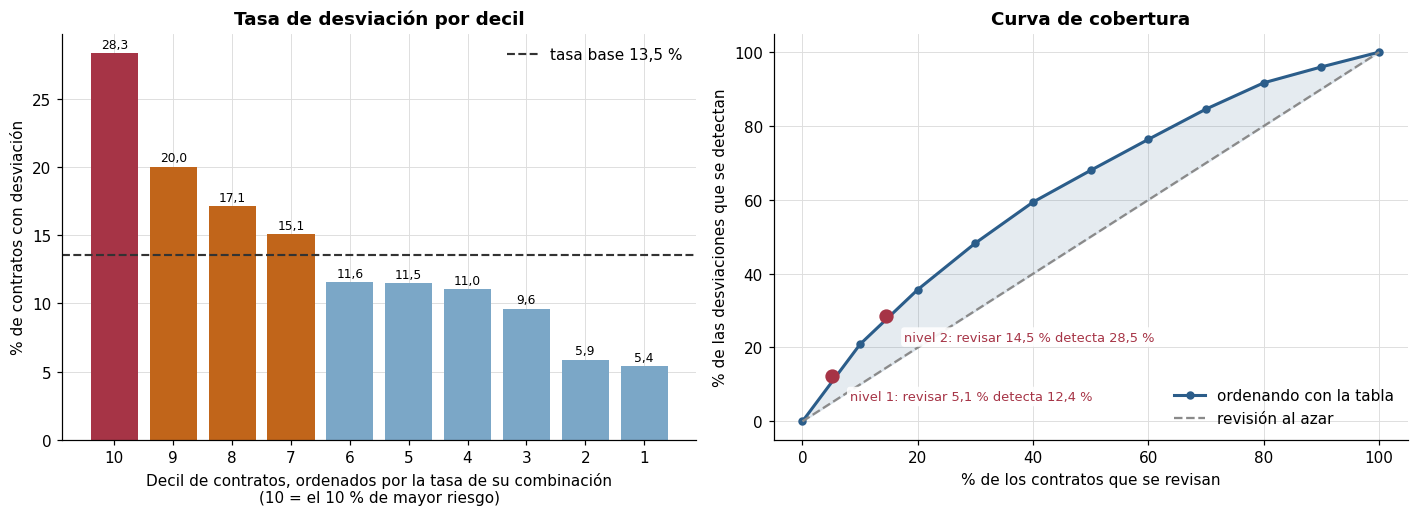

In [5]:
fig, (a1, a2) = plt.subplots(1, 2, figsize=(13, 4.8))

x = np.arange(len(cobertura))
colores = [ROJO if e >= 1.5 else (NARANJA if e >= 1 else AZUL_CLARO)
           for e in cobertura["eficiencia"]]
a1.bar(x, cobertura["tasa_%"], color=colores)
a1.axhline(100 * BASE, color="#333", ls="--", lw=1.4,
           label=f"tasa base {100 * BASE:.1f} %".replace(".", ","))
a1.set_xticks(x, [s.replace("decil ", "") for s in cobertura.index])
a1.set_xlabel("Decil de contratos, ordenados por la tasa de su combinación\n"
              "(10 = el 10 % de mayor riesgo)")
a1.set_ylabel("% de contratos con desviación")
a1.set_title("Tasa de desviación por decil")
a1.legend()
for xi, v in zip(x, cobertura["tasa_%"]):
    a1.text(xi, v + 0.4, f"{v:.1f}".replace(".", ","), ha="center", fontsize=8)

univ = np.concatenate([[0], cobertura["universo_acum_%"].values])
cub = np.concatenate([[0], cobertura["cubiertas_acum_%"].values])
a2.plot(univ, cub, marker="o", ms=4.5, lw=2, color=AZUL, label="ordenando con la tabla")
a2.plot([0, 100], [0, 100], ls="--", color=GRIS, lw=1.5, label="revisión al azar")
a2.fill_between(univ, cub, univ, color=AZUL, alpha=0.12)
for nombre, u, desplazamiento in [("nivel 1", NIVEL_1, (12, -16)), ("nivel 2", NIVEL_2, (12, -16))]:
    fila = umbrales[umbrales["umbral"].str.endswith(f"≥ {u} %")].iloc[0]
    px, py = fila["universo_%"], fila["desviaciones_cubiertas_%"]
    a2.scatter(px, py, s=70, color=ROJO, zorder=4)
    a2.annotate(f"{nombre}: revisar {px:.1f} % detecta {py:.1f} %".replace(".", ","), (px, py),
                textcoords="offset points", xytext=desplazamiento, fontsize=8.5, color=ROJO,
                bbox=dict(boxstyle="round,pad=0.25", fc="white", ec="none", alpha=0.9))
a2.set_xlabel("% de los contratos que se revisan")
a2.set_ylabel("% de las desviaciones que se detectan")
a2.set_title("Curva de cobertura")
a2.legend(loc="lower right")
fig.tight_layout()
print("figura:", guardar(fig, "r_cobertura_focalizacion"))
plt.show()

### Lectura de la cobertura

| Si la oficina revisa… | Detecta… | Eficiencia |
|---|---|---|
| el 5,1 % (nivel 1: combinaciones ≥ 25 %) | 12,4 % de las desviaciones | 2,45× |
| el 10 % de mayor riesgo | **20,9 %** de las desviaciones | 2,09× |
| el 14,5 % (nivel 2: combinaciones ≥ 20 %) | 28,5 % de las desviaciones | 1,96× |
| el 30 % de mayor riesgo | **48,3 %** de las desviaciones | 1,61× |
| el 35,7 % (combinaciones ≥ 15 %) | 55,1 % de las desviaciones | 1,54× |

El decil superior se desvía en el **28,3 %** de los casos, frente al 13,55 % del universo: más del
**doble** que una revisión al azar.

**Sobre la magnitud de la ganancia, sin adornos.** Revisar el 30 % de los contratos para detectar
el 48 % de las desviaciones es una mejora real para un equipo pequeño, pero está lejos de resolver
el problema: más de la mitad de las desviaciones ocurre en contratos que la tabla no señala como
prioritarios.

La razón es estructural y ya la explicó el notebook 03: solo dos atributos discriminan de verdad, y
ambos son características gruesas del contrato. Entre las características de la matriz (sección 13
del notebook 03), ninguna otra supera el umbral de relevancia frente a la desviación. El año de
firma y la duración declarada sí lo superan, pero ninguno sirve como criterio: el año es el mismo
para todos los contratos que se firman hoy, y la duración puede estar contaminada por la propia
adición (sección 12 del notebook 03).

---
## 3. Dos niveles de supervisión

Los umbrales no son pruebas estadísticas: son decisiones de capacidad. Se proponen dos porque
coinciden con reglas fáciles de enunciar, y la celda siguiente comprueba que las reglas en palabras
seleccionan exactamente los mismos contratos que el umbral.

**Nivel 1 — combinaciones con tasa ≥ 25 %.** Todo contrato de **más de 1.000 millones**, en
cualquier modalidad, y los de **200 a 1.000 millones** adjudicados por **licitación pública** o
por **régimen especial con ofertas**.

**Nivel 2 — combinaciones con tasa ≥ 20 %.** Agrega los contratos de 200 a 1.000 millones en toda
modalidad salvo la contratación directa (con o sin ofertas) y el régimen especial sin ofertas, y
los de régimen especial con ofertas de 50 a 200 millones.

En el otro extremo, los **contratos de menos de 10 millones** son candidatos a una revisión
aligerada o por muestreo.

In [6]:
# Las reglas en palabras deben seleccionar exactamente los mismos contratos que el umbral.
CON_OFERTAS_O_LICITACION = ["Licitación pública", "Contratación régimen especial (con ofertas)"]
FUERA_DEL_NIVEL_2 = ["Contratación directa", "Contratación directa (con ofertas)",
                     "Contratación régimen especial"]
mas_de_1000 = d["banda_valor"] == "> 1.000 M"
de_200_a_1000 = d["banda_valor"] == "200–1.000 M"
regla_1 = mas_de_1000 | (de_200_a_1000 & d["modalidad"].isin(CON_OFERTAS_O_LICITACION))
regla_2 = (regla_1
           | (de_200_a_1000 & ~d["modalidad"].isin(FUERA_DEL_NIVEL_2))
           | ((d["banda_valor"] == "50–200 M")
              & (d["modalidad"] == "Contratación régimen especial (con ofertas)")))
assert regla_1.equals(d["tasa_regla_%"] >= NIVEL_1), "la regla del nivel 1 no coincide"
assert regla_2.equals(d["tasa_regla_%"] >= NIVEL_2), "la regla del nivel 2 no coincide"
print("las reglas en palabras coinciden con los umbrales de la tabla\n")

menos_de_10 = d["banda_valor"] == "< 10 M"
niveles = pd.DataFrame([
    {"grupo": nombre, "contratos": int(sel.sum()),
     "universo_%": round(100 * sel.mean(), 1),
     "tasa_del_grupo_%": round(100 * d.loc[sel, "y"].mean(), 2),
     "desviaciones_cubiertas_%": round(100 * d.loc[sel, "y"].sum() / d["y"].sum(), 1),
     "eficiencia": round(d.loc[sel, "y"].mean() / BASE, 2)}
    for nombre, sel in [("nivel 1", regla_1), ("nivel 2", regla_2),
                        ("menos de 10 millones", menos_de_10)]
]).set_index("grupo")
display(niveles)

las reglas en palabras coinciden con los umbrales de la tabla



,contratos,universo_%,tasa_del_grupo_%,desviaciones_cubiertas_%,eficiencia
grupo,,,,,
nivel 1,9968,5.1,33.22,12.4,2.45
nivel 2,28493,14.5,26.61,28.5,1.96
menos de 10 millones,42069,21.4,5.82,9.2,0.43


figura: reports/figures/r_tabla_riesgo.png


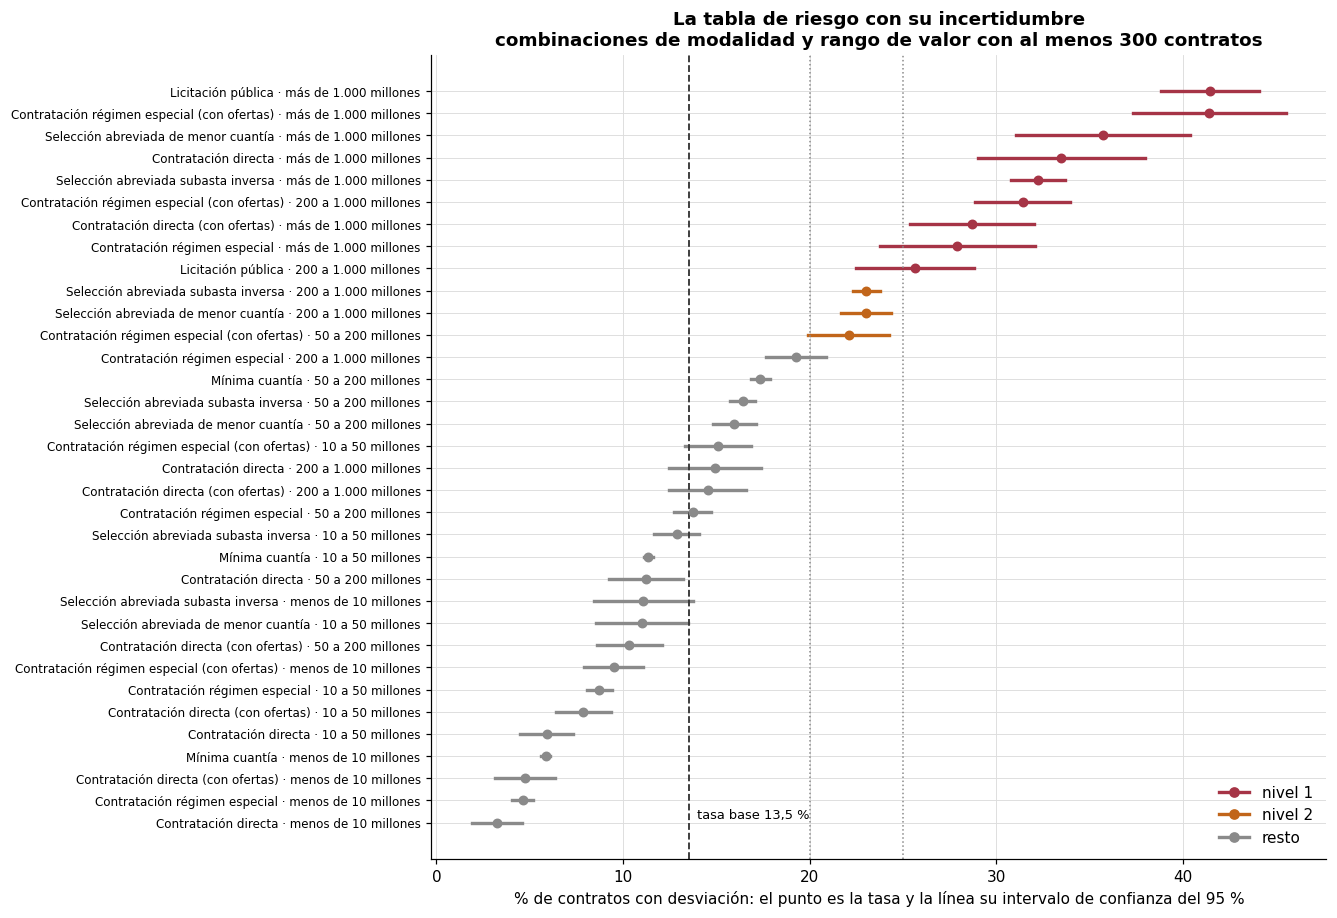

In [7]:
# La tabla de riesgo con su incertidumbre: cada combinacion estable y su IC 95 %.
g = estables.sort_values("tasa_%").reset_index(drop=True)
nivel = np.where(g["tasa_regla_%"] >= NIVEL_1, "nivel 1",
                 np.where(g["tasa_regla_%"] >= NIVEL_2, "nivel 2", "resto"))
COLOR_NIVEL = {"nivel 1": ROJO, "nivel 2": NARANJA, "resto": GRIS}

fig, ax = plt.subplots(figsize=(10.5, 9.5))
for k, fila in g.iterrows():
    color = COLOR_NIVEL[nivel[k]]
    ax.plot([fila["IC_lo_%"], fila["IC_hi_%"]], [k, k], color=color, lw=2.2)
    ax.scatter(fila["tasa_%"], k, color=color, s=30, zorder=3)
ax.set_yticks(range(len(g)),
              [f"{m} · {ETIQ_TEXTO[b]}" for m, b in zip(g["modalidad"], g["banda_valor"])],
              fontsize=7.8)
ax.axvline(100 * BASE, color="#333", ls="--", lw=1.2)
ax.text(100 * BASE + 0.4, 0.2, f"tasa base {100 * BASE:.1f} %".replace(".", ","), fontsize=8.5)
for u in (NIVEL_2, NIVEL_1):
    ax.axvline(u, color=GRIS, ls=":", lw=1)
ax.set_xlabel("% de contratos con desviación: el punto es la tasa y la línea su intervalo de "
              "confianza del 95 %")
ax.set_title("La tabla de riesgo con su incertidumbre\n"
             "combinaciones de modalidad y rango de valor con al menos 300 contratos")
ax.legend(handles=[Line2D([0], [0], color=c, lw=2.2, marker="o", label=n)
                   for n, c in COLOR_NIVEL.items()], loc="lower right")
print("figura:", guardar(fig, "r_tabla_riesgo"))
plt.show()

### Lectura de los niveles

| Grupo | Contratos | % del universo | Se desvía | Detecta | Eficiencia |
|---|---|---|---|---|---|
| **Nivel 1** | 9.968 | 5,1 % | **33,2 %** (uno de cada tres) | 12,4 % | 2,45× |
| **Nivel 2** | 28.493 | 14,5 % | **26,6 %** (uno de cada cuatro) | 28,5 % | 1,96× |
| Menos de 10 millones | 42.069 | 21,4 % | 5,8 % | 9,2 % | 0,43× |

Los intervalos del nivel 1 quedan todos muy por encima de la tasa base: su riesgo no es un
accidente de la muestra. Los más anchos son los de las combinaciones con pocos contratos, casi
todas por encima de 1.000 millones, y aun el más ancho (±4,7 puntos) deja su combinación lejos de
la tasa base.

En el otro extremo, los contratos de menos de 10 millones son la quinta parte del universo y
concentran menos de la décima parte de las desviaciones. Revisarlos por muestreo libera el
esfuerzo que financia la supervisión estrecha de los niveles 1 y 2.

---
## 4. Segundo frente: calidad del reporte

El hallazgo con mayor tamaño de efecto de las pruebas primarias no es sobre la ejecución de los
contratos sino sobre **su registro**. Responde a la pregunta H8 del notebook 03, *¿dejar de
registrar pagos se concentra en ciertos tipos de entidad o sectores?*, y la respuesta es sí para
el sector (V = 0,222). Merece un frente propio porque
se corrige con otras herramientas: requerimientos de reporte, no supervisión de ejecución.

In [8]:
frente = (df.groupby("sector", observed=True)
          .agg(contratos=("pago_cero", "size"),
               sin_reporte_pct=("pago_cero", "mean"),
               desviacion_pct=("desviacion", "mean"))
          .query("contratos >= 1000"))
# Tasa esperada de cada sector por su mezcla de modalidad y rango de valor, como en el
# control por composicion del notebook 03 (seccion 12).
tasa_celda = d.groupby(["modalidad", "banda_valor"], observed=True)["y"].transform("mean")
esperada = d.assign(esperada=tasa_celda).groupby("sector", observed=True)["esperada"].mean()
frente["sin_reporte_%"] = (100 * frente["sin_reporte_pct"]).round(1)
frente["desviacion_%"] = (100 * frente["desviacion_pct"]).round(2)
frente["esperada_%"] = (100 * esperada.reindex(frente.index)).round(2)
frente = frente.sort_values("sin_reporte_%", ascending=False)
COLS_FRENTE = ["contratos", "sin_reporte_%", "desviacion_%", "esperada_%"]
display(frente[COLS_FRENTE])

frente[COLS_FRENTE].to_csv(config.TABLAS / "frente_calidad_reporte.csv", encoding="utf-8")
print("escrito: reports/tablas/frente_calidad_reporte.csv")

,contratos,sin_reporte_%,desviacion_%,esperada_%
sector,,,,
Salud y protección social,22037,74.2,13.31,13.54
Interior,1172,72.9,13.40,11.51
Agricultura,1254,72.5,12.76,14.39
Transporte,4655,70.1,10.76,14.34
Minas y energía,1025,64.5,17.27,16.07
"Vivienda, ciudad y territorio",1497,64.0,14.50,12.46
Industria,1807,61.4,11.01,13.58
Presidencia de la república,1000,58.4,6.80,13.96
Ley de justicia,20377,57.3,10.33,11.18


escrito: reports/tablas/frente_calidad_reporte.csv


figura:

 reports/figures/r_sesgo_reporte_vs_desviacion.png


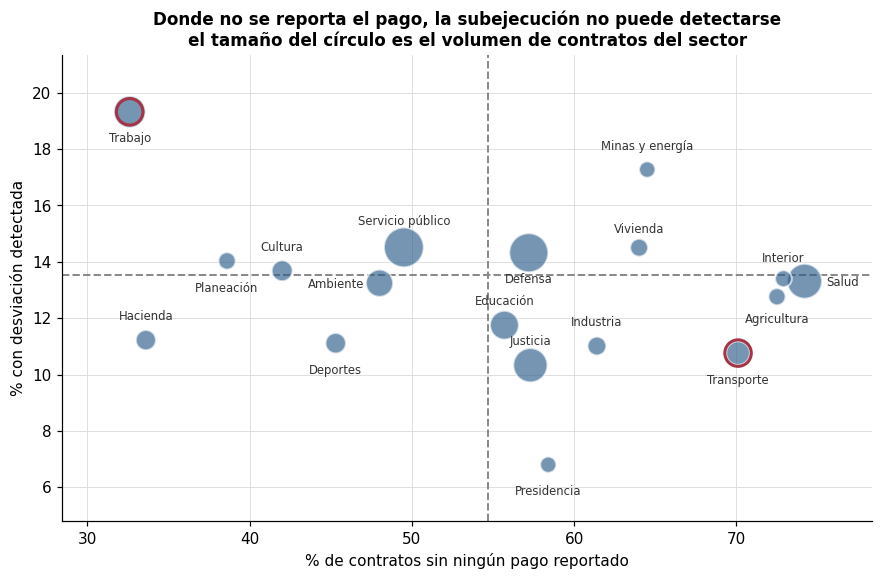

Correlación de Spearman entre no-reporte y desviación detectada:
  rho = -0.170   p = 0.499   n = 18 sectores
  IC 95 % = [-0.610, 0.349]   -> incluye el cero, asi que el signo no esta establecido

NO es significativa. Con solo 18 sectores no hay potencia para establecer
una relacion agregada, y no debe presentarse como evidencia del sesgo.
El signo es el esperado, pero eso es todo lo que se puede afirmar.

El sesgo de medicion se sostiene en dos cosas distintas y mas solidas:
  1. Por construccion: subejecucion_parcial exige pago > 0. En la zona
     ciega la senal es estructuralmente indetectable, no baja.
  2. Los extremos. Transporte no reporta pago en el 70.1 % de sus
     contratos y se desvia menos de lo esperado (10.8 % frente a 14.3 %).
     Trabajo, el que mejor reporta (32.6 %), se desvia mas (19.3 % frente a 13.3 %).

Reportan peor que la media (54.7 % sin pago): 11 sectores, 8 se desvian menos de lo esperado
Reportan mejor: 7 sectores, 2 se desvian menos de lo esperado

Co

In [9]:
fig, ax = plt.subplots(figsize=(9.5, 5.5))
ax.scatter(frente["sin_reporte_%"], frente["desviacion_%"],
           s=np.sqrt(frente["contratos"]) * 3.5, color=AZUL, alpha=0.65,
           edgecolor="white", linewidth=1.3, zorder=3)
# Nombres cortos, y las etiquetas alternadas arriba/abajo para que los sectores
# vecinos no se solapen. Los del grupo mas denso llevan una posicion fija.
CORTO = {"Salud y protección social": "Salud", "Ambiente y desarrollo sostenible": "Ambiente",
         "Vivienda, ciudad y territorio": "Vivienda", "Presidencia de la república": "Presidencia",
         "Hacienda y crédito público": "Hacienda", "Educación nacional": "Educación",
         "Ley de justicia": "Justicia", "Servicio público": "Servicio público"}
FIJA = {"Salud y protección social": ((14, -3), "left"), "Interior": ((0, 11), "center"),
        "Agricultura": ((0, -17), "center"), "Ambiente y desarrollo sostenible": ((-10, -3), "right"),
        "Servicio público": ((0, 15), "center"), "Vivienda, ciudad y territorio": ((0, 10), "center")}
orden_x = frente["sin_reporte_%"].rank(method="first").astype(int)
for i, (nombre, row) in enumerate(frente.iterrows()):
    arriba = orden_x.iloc[i] % 2 == 0
    desplazamiento, alineacion = FIJA.get(nombre, ((0, 13 if arriba else -20), "center"))
    ax.annotate(CORTO.get(nombre, str(nombre)), (row["sin_reporte_%"], row["desviacion_%"]),
                textcoords="offset points", xytext=desplazamiento,
                ha=alineacion, fontsize=7.6, color="#333")
ax.margins(x=0.10, y=0.16)

ax.axvline(100 * df["pago_cero"].mean(), color=GRIS, ls="--", lw=1.3)
ax.axhline(100 * df["desviacion"].mean(), color=GRIS, ls="--", lw=1.3)
ax.set_xlabel("% de contratos sin ningún pago reportado")
ax.set_ylabel("% con desviación detectada")
ax.set_title("Donde no se reporta el pago, la subejecución no puede detectarse\n"
             "el tamaño del círculo es el volumen de contratos del sector", fontsize=11)

# Se destacan los dos extremos que sustentan el argumento: Transporte reporta mal
# y se desvia menos de lo esperado; Trabajo reporta mejor que nadie y se desvia mas.
for nombre in ["Transporte", "Trabajo"]:
    if nombre in frente.index:
        row = frente.loc[nombre]
        ax.scatter([row["sin_reporte_%"]], [row["desviacion_%"]], s=300,
                   facecolor="none", edgecolor=ROJO, linewidth=2, zorder=4)
print("figura:", guardar(fig, "r_sesgo_reporte_vs_desviacion"))
plt.show()

# Numerica vs numerica: la rama del arbol de decision que corresponde al
# Correlation Test. Se pide el IC 95 %, que es lo que deja ver la falta de
# potencia con solo 18 sectores.
r_sec = prueba_correlacion(frente.reset_index(), "sin_reporte_pct", "desviacion_pct",
                           "spearman", "frente-calidad")
rho, p_rho = r_sec["valor_efecto"], r_sec["p"]
print(f"Correlación de Spearman entre no-reporte y desviación detectada:")
print(f"  rho = {rho:.3f}   p = {p_rho:.3f}   n = {len(frente)} sectores")
print(f"  IC 95 % = [{r_sec['IC_lo']:.3f}, {r_sec['IC_hi']:.3f}]   "
      f"-> incluye el cero, asi que el signo no esta establecido")
print()
if p_rho >= 0.05:
    print("NO es significativa. Con solo 18 sectores no hay potencia para establecer")
    print("una relacion agregada, y no debe presentarse como evidencia del sesgo.")
    print("El signo es el esperado, pero eso es todo lo que se puede afirmar.")
print()
tr, tb = frente.loc["Transporte"], frente.loc["Trabajo"]
print("El sesgo de medicion se sostiene en dos cosas distintas y mas solidas:")
print("  1. Por construccion: subejecucion_parcial exige pago > 0. En la zona")
print("     ciega la senal es estructuralmente indetectable, no baja.")
print(f"  2. Los extremos. Transporte no reporta pago en el {tr['sin_reporte_%']:.1f} % de sus")
print(f"     contratos y se desvia menos de lo esperado ({tr['desviacion_%']:.1f} % frente a "
      f"{tr['esperada_%']:.1f} %).")
print(f"     Trabajo, el que mejor reporta ({tb['sin_reporte_%']:.1f} %), se desvia mas "
      f"({tb['desviacion_%']:.1f} % frente a {tb['esperada_%']:.1f} %).")
print()
# El patron completo y no solo los extremos: cuantos sectores se desvian menos de lo
# esperado entre los que reportan peor que la media y entre los que reportan mejor.
media_sin_reporte = 100 * df["pago_cero"].mean()
razon = frente["desviacion_%"] / frente["esperada_%"]
peor = frente["sin_reporte_%"] > media_sin_reporte
print(f"Reportan peor que la media ({media_sin_reporte:.1f} % sin pago): {peor.sum()} sectores, "
      f"{(razon[peor] < 1).sum()} se desvian menos de lo esperado")
print(f"Reportan mejor: {(~peor).sum()} sectores, "
      f"{(razon[~peor] < 1).sum()} se desvian menos de lo esperado")
print()
print("Contraejemplos que conviene declarar: reportan peor que la media y aun asi se")
print("desvian mas de lo esperado. El sesgo no es universal.")
for nombre in frente.index[peor & (razon > 1)]:
    row = frente.loc[nombre]
    print(f"  {nombre}: {row['sin_reporte_%']:.1f} % sin pago; se desvia el "
          f"{row['desviacion_%']:.1f} % frente a {row['esperada_%']:.1f} % esperado")

### Conclusión del segundo frente, con el alcance que los datos permiten

**Lo que sí está establecido.** La zona ciega de reporte se concentra fuertemente por sector, y
esa es la asociación de mayor tamaño de efecto de las pruebas primarias: **V = 0,222** (H8,
notebook 03), con Salud y protección social en el 74,2 %, Interior en el 72,9 % y Agricultura en
el 72,5 %, frente a una media del 54,7 %.

**Lo que NO está establecido, y conviene no exagerar.** La correlación a nivel de sector entre
no-reporte y desviación detectada es de ρ = −0,17 con **p = 0,50** (IC 95 % [−0,61; 0,35]): aun
sin ninguna relación real, una correlación así saldría por casualidad la mitad de las veces. Con
solo 18 sectores no hay potencia para afirmar una relación agregada. El signo apunta en la
dirección esperada, pero eso es cuanto puede decirse. **No usamos esa correlación como
evidencia.**

**El argumento del sesgo de medición se sostiene en otras dos cosas, más sólidas:**

1. **Por construcción.** `subejecucion_parcial` exige `pago > 0`. En la zona ciega la señal no
   es baja, es *estructuralmente indetectable*. No hace falta correlación alguna para afirmarlo.
2. **Por los extremos.** Transporte no registra pago en el 70,1 % de sus contratos y se desvía
   menos de lo que anticipa su mezcla de valor y modalidad (10,8 % frente a 14,3 %). Trabajo, el
   sector que mejor reporta (32,6 % sin pago), se desvía más de lo esperado (19,3 % frente a
   13,3 %). Son comparaciones con miles de contratos detrás, no una correlación sobre 18 puntos.

**Y los contraejemplos que hay que declarar.** El patrón va en la dirección esperada, pero no es
unánime: de los 11 sectores que reportan peor que la media, 8 se desvían menos de lo que anticipa
su mezcla, frente a 2 de los 7 que reportan mejor. Interior (72,9 % sin pago), Minas y energía
(64,5 %) y Vivienda (64,0 %) reportan mal y aun así se desvían más de lo esperado (13,4 % frente
a 11,5 %; 17,3 % frente a 16,1 %; 14,5 % frente a 12,5 %). El sesgo no opera en todos los
sectores por igual.

**Recomendación.** Antes de desatender a un sector porque su tasa de desviación es baja, exigirle
el registro completo de pagos y recalcular. La ausencia de hallazgos en un sector que no reporta
no es evidencia de cumplimiento.

---
## 5. Entregables generados

Tablas exportadas para el informe ejecutivo.

In [10]:
print("Tablas en reports/tablas/:")
for p in sorted(config.TABLAS.glob("*.csv")):
    print(f"  {p.name:36} {p.stat().st_size / 1024:>7.1f} KB")

print("\nFiguras en reports/figures/:")
for p in sorted(config.FIGURAS.glob("*.png")):
    print(f"  {p.name:38} {p.stat().st_size / 1024:>7.1f} KB")

Tablas en reports/tablas/:
  bitacora_tratamiento.csv                 5.5 KB
  chequeos_integridad.csv                  1.7 KB
  cobertura_focalizacion.csv               0.5 KB
  combinaciones_riesgo.csv                 3.6 KB
  control_composicion.csv                  2.2 KB
  control_destino_por_valor.csv            1.0 KB
  frente_calidad_reporte.csv               0.8 KB
  matriz_asociacion.csv                    4.3 KB
  perfilado_columnas.csv                   3.6 KB
  pruebas_hipotesis.csv                    1.5 KB
  pruebas_robustez.csv                     0.5 KB
  sensibilidad_periodo.csv                10.3 KB
  umbrales_focalizacion.csv                0.4 KB
  validacion_supuestos.csv                 1.5 KB

Figuras en reports/figures/:
  c_reglas_integridad.png                  140.2 KB
  control_destino_por_valor.png             64.7 KB
  d_completitud_aparente_vs_efectiva.png    78.7 KB
  e_estado_por_anio.png                     35.4 KB
  e_registro_por_mes.png           

---
## Recomendación final a la oficina de control interno

**Criterios de focalización, en orden de potencia demostrada:**

1. **Valor del contrato.** El criterio más potente y el más simple. La tasa de desviación pasa
   del 4,2 % en el decil más bajo al 28,2 % en el más alto (H2), y los contratos que se desvían
   valen 2,81 veces más que los que no (H2b). Por encima de 1.000 millones, uno de cada tres se
   desvía.
2. **Modalidad de contratación.** Licitación pública (25,8 % de adición de plazo) y régimen
   especial con ofertas frente a contratación directa (7,5 %), H1. Conocida en el momento de la
   firma y sin ambigüedad de clasificación.
3. **Los dos juntos, en la tabla de riesgo.** El nivel 1 (5,1 % de los contratos) detecta el
   12,4 % de las desviaciones, con una eficiencia de 2,45×; el nivel 2 (14,5 %), el 28,5 %, con
   1,96×. Revisar el 30 % de mayor riesgo detecta el 48,3 %.
4. **Alerta específica:** los **13.726 contratos con adición de plazo pese a estar marcados como
   no prorrogables**. O el dato está mal capturado o se adicionó plazo sin habilitación
   contractual; en ambos casos merece revisión.

**Criterios que el análisis descarta, y conviene decirlo explícitamente:**

*Para leer los valores p de esta lista: el valor p dice qué tan raro sería ver una diferencia así
solo por casualidad si en realidad no hubiera ninguna relación. Por debajo de 0,05 (menos de 1 en
20) el resultado se llama «significativo». Significativo no quiere decir importante: con 196.000
contratos, casi cualquier diferencia lo es.*

- **El destino del gasto** (Funcionamiento / Inversión), que el enunciado sugería como candidato:
  cerca de la mitad de su diferencia bruta es composición —la inversión firma contratos más
  caros— y lo que queda no llega al umbral de relevancia en ningún rango de valor (V ≤ 0,045;
  notebook 03, §12).
- **El orden de la entidad**: la diferencia no es casualidad (p = 6,7 × 10⁻¹¹), pero el efecto
  es despreciable (V = 0,015), sin capacidad de discriminación práctica.
- **El tipo de contrato y la prorrogabilidad**: la prorrogabilidad queda por debajo del umbral
  (V = 0,057), y la asociación de los suministros con la subejecución parece propia de la forma
  del contrato y no un indicio de riesgo (notebook 03, §13).
- **Los atributos del representante legal.** El género resultó «significativo» (p = 0,0009) con
  una diferencia de 0,43 puntos porcentuales. Usarlo para focalizar sería estadísticamente
  injustificado y éticamente inaceptable.

**Limitaciones que condicionan todo lo anterior:**

1. **La zona ciega.** El 54,7 % de los contratos no registra ningún pago, y los datos no permiten
   distinguir «no se ejecutó» de «no se reportó». Toda tasa de desviación de este informe es un
   **piso**, no una estimación del incumplimiento real.
2. **El sesgo de medición por sector**, documentado en la sección 4: donde no se reporta, no se
   detecta.
3. **Discriminación moderada.** Revisar el 30 % de los contratos detecta el 48 % de las
   desviaciones: más de la mitad ocurre en contratos que la tabla no señala como prioritarios.
4. **Valores nominales sin deflactar.** Los rangos en pesos corrientes mezclan siete años con
   inflación acumulada considerable; los cortes de la tabla deben revisarse periódicamente.
5. **Asociación, no causalidad.** Nada de esto identifica el mecanismo por el que un contrato se
   desvía. Sirve para priorizar a quién mirar, no para atribuir responsabilidad.
6. **Deriva temporal fuerte.** La tasa de desviación pasa del 8,0 % en 2019 al 21,7 % en 2025, y
   2025 se desvía un 54 % más de lo que anticipa su mezcla de valor y modalidad (notebook 03, §12).
   Puede reflejar un cambio en el registro de las modificaciones más que un empeoramiento real, y
   los datos no permiten separar una cosa de la otra. En cualquier caso, la tabla de riesgo
   envejece y debe recalcularse al menos una vez al año.